# Autoregressive Text Generation on *The Devil's Dictionary*
### Foundations of Generative AI (ICT4403) · Assignment 2
**Comparing Simple RNN, Bidirectional RNN, LSTM and GRU for next-word prediction & sequential generation**

**Objective.** Build a word-level autoregressive language model, train four recurrent architectures under identical
conditions, compare them quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence,
diversity, contextual consistency, repetition), and analyse how sampling temperature shapes the generated text.

**Dataset.** Ambrose Bierce, *The Devil's Dictionary* (1911) — Project Gutenberg eBook #972
(<https://www.gutenberg.org/ebooks/972>, raw text: <https://www.gutenberg.org/cache/epub/972/pg972.txt>).
A satirical dictionary of ~1,000 cynical definitions interleaved with mock-heroic verse, rarely used in
text-generation work and with a distinctive, highly regular structure (`HEADWORD, pos. definition`).

In [1]:
import os, sys, json, time
import torch, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
sys.path.insert(0, os.path.abspath("."))

from src.data import prepare_corpus, strip_gutenberg, load_raw, detokenize
from src.models import build_model, count_params, MODEL_SPECS
from src.train import TrainConfig
from src.experiment import (describe_dataset, plot_dataset, train_all, plot_training,
                            plot_comparison, temperature_study, plot_temperature, SEEDS, TEMPERATURES)

cfg = TrainConfig()
torch.set_num_threads(cfg.threads)
pd.set_option("display.precision", 4)
print("PyTorch", torch.__version__, "| device: CPU | threads:", torch.get_num_threads())
cfg

PyTorch 2.14.0+cpu | device: CPU | threads: 6


TrainConfig(seq_len=20, train_stride=2, emb_dim=128, hidden=256, layers=2, dropout=0.3, batch_size=256, lr=0.003, weight_decay=0.0, clip=1.0, max_epochs=15, patience=3, seed=42, threads=6)

## 1. Dataset characteristics & preprocessing
**Pre-processing pipeline** (`src/data.py`):
1. Remove the Project Gutenberg licence header/footer and the author's preface → keep only dictionary entries (ABASEMENT … ZOOLOGY).
2. Drop alphabet section headers (`A`, `B`, …), italics markers (`_word_`), normalise curly quotes/dashes, lowercase.
3. Preserve document structure with two special tokens: `<par>` (paragraph/entry boundary) and `<nl>` (line break inside indented verse).
4. Regex word-level tokenisation; punctuation (`, . ; : ! ? " ( ) --`) kept as separate tokens so the model can learn the `word, n.` definition format.
5. Vocabulary: tokens with frequency ≥ 2 (rarer words → `<unk>`; `<unk>` targets are removed from training/eval and never sampled).

In [2]:
raw = load_raw("data/devils_dictionary.txt")
print("Raw excerpt:\n" + "-"*60)
print(strip_gutenberg(raw)[:700])
corpus = prepare_corpus(seq_len=cfg.seq_len, train_stride=cfg.train_stride)
print("\nTokenised (first 45 tokens):\n", corpus.tokens[:45])
describe_dataset(corpus)

Raw excerpt:
------------------------------------------------------------
ABASEMENT, n.  A decent and customary mental attitude in the presence
of wealth or power.  Peculiarly appropriate in an employee when
addressing an employer.

ABATIS, n.  Rubbish in front of a fort, to prevent the rubbish outside
from molesting the rubbish inside.

ABDICATION, n.  An act whereby a sovereign attests his sense of the
high temperature of the throne.

  Poor Isabella's dead, whose abdication
  Set all tongues wagging in the Spanish nation.
  For that performance 'twere unfair to scold her:
  She wisely left a throne too hot to hold her.
  To History she'll be no royal riddle--
  Merely a plain parched pea that jumped the griddle.

G.J.


ABDOMEN, n.  The temple of the god Stomac

Tokenised (first 45 tokens):
 ['abasement', ',', 'n', '.', 'a', 'decent', 'and', 'customary', 'mental', 'attitude', 'in', 'the', 'presence', 'of', 'wealth', 'or', 'power', '.', 'peculiarly', 'appropriate', 'in', 'an', 'emplo

,statistic,value
0,characters (cleaned),373203.000
1,total tokens,75278.000
2,word tokens,60053.000
3,unique tokens (types),11200.000
4,vocab size (min_freq applied),4731.000
5,hapax legomena (freq=1),6471.000
6,<unk> rate after vocab cap,0.086
7,dictionary entries (approx.),980.000
8,verse line breaks (<nl>),2146.000
9,paragraphs (<par>),1734.000


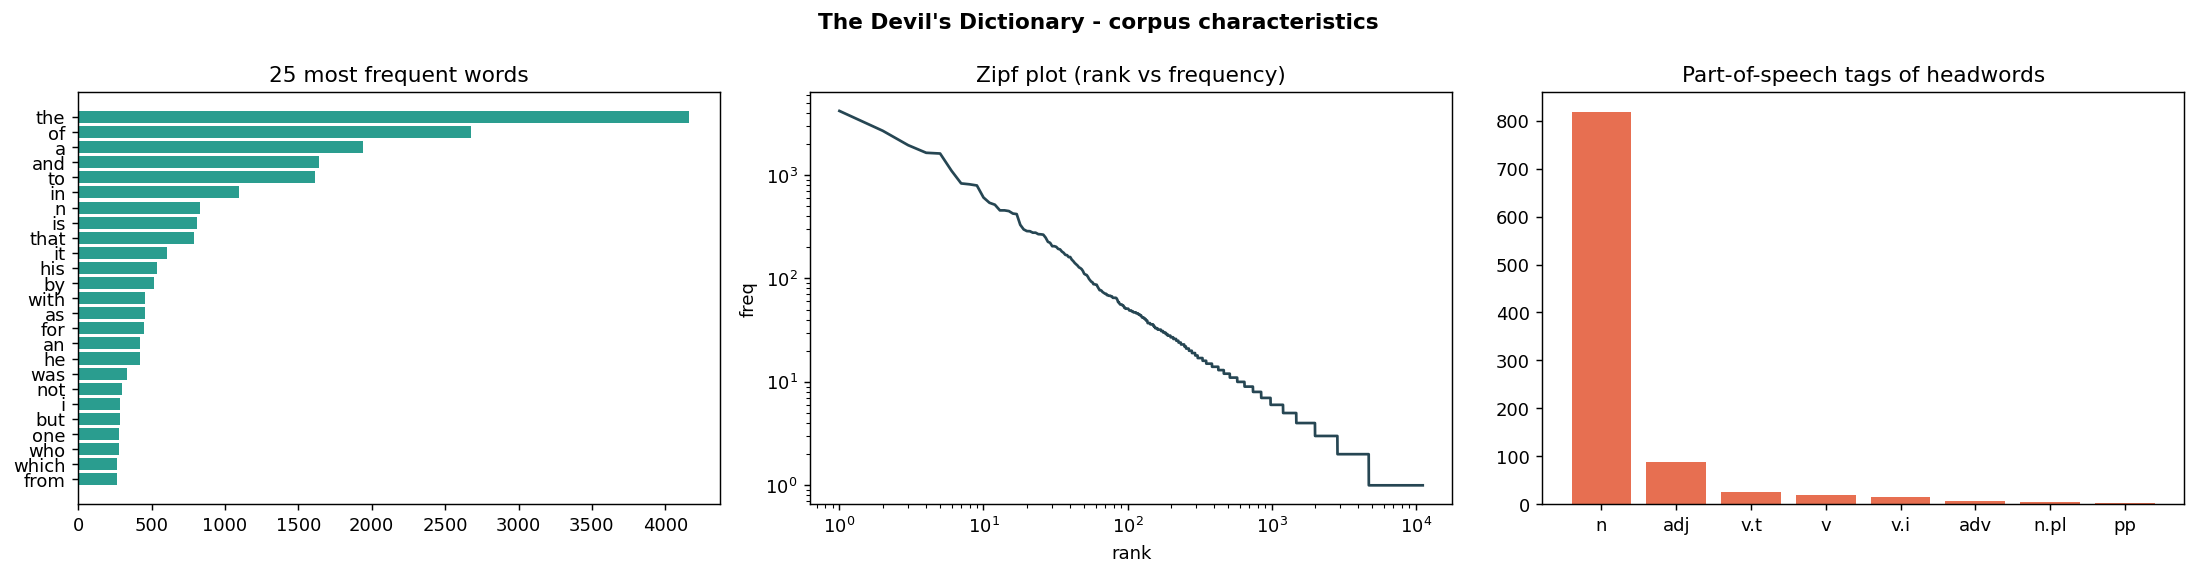

In [3]:
display(Image(plot_dataset(corpus)))

**Observations.** The corpus is small (~75 k tokens) with a long-tailed (Zipfian) vocabulary: more than half of all word types
occur only once, typical of Bierce's ornate, archaic diction. Nouns dominate the headwords. Roughly a quarter of the text is verse
(each `<nl>` is a verse line break), so a model must handle two registers — terse prose definitions and rhymed couplets.

### Input → target sequences for autoregressive modelling
The token stream is cut into contiguous blocks of 2,000 tokens; blocks are assigned 8:1:1 to train / validation / test in a
round-robin way, so every split spans the whole alphabet and no window crosses a split boundary (no leakage).
Inside each block a sliding window produces pairs **X = w<sub>t-20</sub> … w<sub>t-1</sub> → y = w<sub>t</sub>**
(context length 20; training stride 2 to fit a CPU budget, validation/test stride 1).

In [4]:
X, y = corpus.datasets["train"][:3]
for xi, yi in zip(X, y):
    print(" ".join(corpus.vocab.decode(xi)), "  ──►  ", corpus.vocab.itos[yi])
print({k: tuple(v.tensors[0].shape) for k, v in corpus.datasets.items()})

<unk> , n . a decent and customary mental attitude in the presence of wealth or power . peculiarly appropriate   ──►   in
and customary mental attitude in the presence of wealth or power . peculiarly appropriate in an <unk> when <unk> an   ──►   employer
mental attitude in the presence of wealth or power . peculiarly appropriate in an <unk> when <unk> an employer .   ──►   <par>
{'train': (28627, 20), 'val': (5454, 20), 'test': (5399, 20)}


## 2. Models
All four share **Embedding(128) → 2-layer recurrent core (hidden 256, dropout 0.3) → Dropout → Linear(|V|)**; only the core differs:

| Model | Core | Notes |
|---|---|---|
| SimpleRNN | `nn.RNN(tanh)` | Elman RNN, prone to vanishing gradients |
| BiRNN | `nn.RNN(bidirectional=True)` | Reads the *context window* left→right and right→left; features = [fwd state at last step ‖ bwd state at first step]. Only past tokens are visible, so it remains a valid (causal) next-word predictor. |
| LSTM | `nn.LSTM` | Input/forget/output gates + cell state |
| GRU | `nn.GRU` | Update/reset gates, fewer parameters than LSTM |

In [5]:
for name in MODEL_SPECS:
    m = build_model(name, len(corpus.vocab), **cfg.model_hparams())
    print(f"{name:10s} {count_params(m):>10,} parameters   core: {m.rnn}")

SimpleRNN   2,051,835 parameters   core: RNN(128, 256, num_layers=2, batch_first=True, dropout=0.3)
BiRNN       3,624,443 parameters   core: RNN(128, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
LSTM        2,743,035 parameters   core: LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3)
GRU         2,512,635 parameters   core: GRU(128, 256, num_layers=2, batch_first=True, dropout=0.3)


## 3. Training under identical conditions
Same data order, same initialisation seed (42), Adam (lr 3e-3), batch 256, cross-entropy loss, gradient clipping 1.0,
ReduceLROnPlateau (×0.5), early stopping on validation loss (patience 3, max 15 epochs) — the best-validation checkpoint is
restored and evaluated on the untouched **test** split. Perplexity = exp(mean cross-entropy).

In [6]:
t0 = time.time()
models, hist, summ = train_all(corpus, cfg)
print(f"\nTotal wall time: {(time.time()-t0)/60:.1f} min")

[SimpleRNN] ep  1 | train 6.557 (ppl   704.3) | val 6.189 (ppl   487.2, top1 0.104) |  15.5s


[SimpleRNN] ep  2 | train 6.072 (ppl   433.5) | val 6.051 (ppl   424.4, top1 0.135) |  16.3s


[SimpleRNN] ep  3 | train 5.788 (ppl   326.5) | val 5.934 (ppl   377.8, top1 0.157) |  14.3s


[SimpleRNN] ep  4 | train 5.604 (ppl   271.4) | val 5.918 (ppl   371.7, top1 0.163) |  15.3s


[SimpleRNN] ep  5 | train 5.439 (ppl   230.2) | val 5.910 (ppl   368.7, top1 0.171) |  14.5s


...

[GRU      ] ep  5 | train 5.235 (ppl   187.8) | val 5.759 (ppl   316.9, top1 0.171) |  36.6s


[GRU      ] ep  6 | train 4.903 (ppl   134.7) | val 5.796 (ppl   328.9, top1 0.174) |  32.7s


[GRU      ] ep  7 | train 4.611 (ppl   100.5) | val 5.825 (ppl   338.8, top1 0.180) |  35.8s


[GRU      ] ep  8 | train 4.227 (ppl    68.5) | val 5.892 (ppl   362.0, top1 0.183) |  38.3s
[GRU      ] early stop (best epoch 5)



Total wall time: 17.2 min


## 4. Quantitative evaluation

In [7]:
summ.style.format(precision=3).highlight_min(subset=["test_loss","test_ppl","total_train_time_s"], color="#c7f0d8") \
    .highlight_max(subset=["test_top1_acc","test_top5_acc"], color="#c7f0d8")

,params,epochs_run,best_epoch,val_loss,val_ppl,test_loss,test_ppl,test_top1_acc,test_top5_acc,total_train_time_s,time_per_epoch_s
model,,,,,,,,,,,
SimpleRNN,2051835,8,5,5.910,368.704,6.051,424.663,0.173,0.343,128.195,16.024
BiRNN,3624443,4,1,5.851,347.511,5.923,373.673,0.166,0.326,163.490,40.872
LSTM,2743035,9,6,5.594,268.735,5.703,299.671,0.179,0.353,385.303,42.811
GRU,2512635,8,5,5.759,316.929,5.880,357.807,0.181,0.354,282.125,35.266


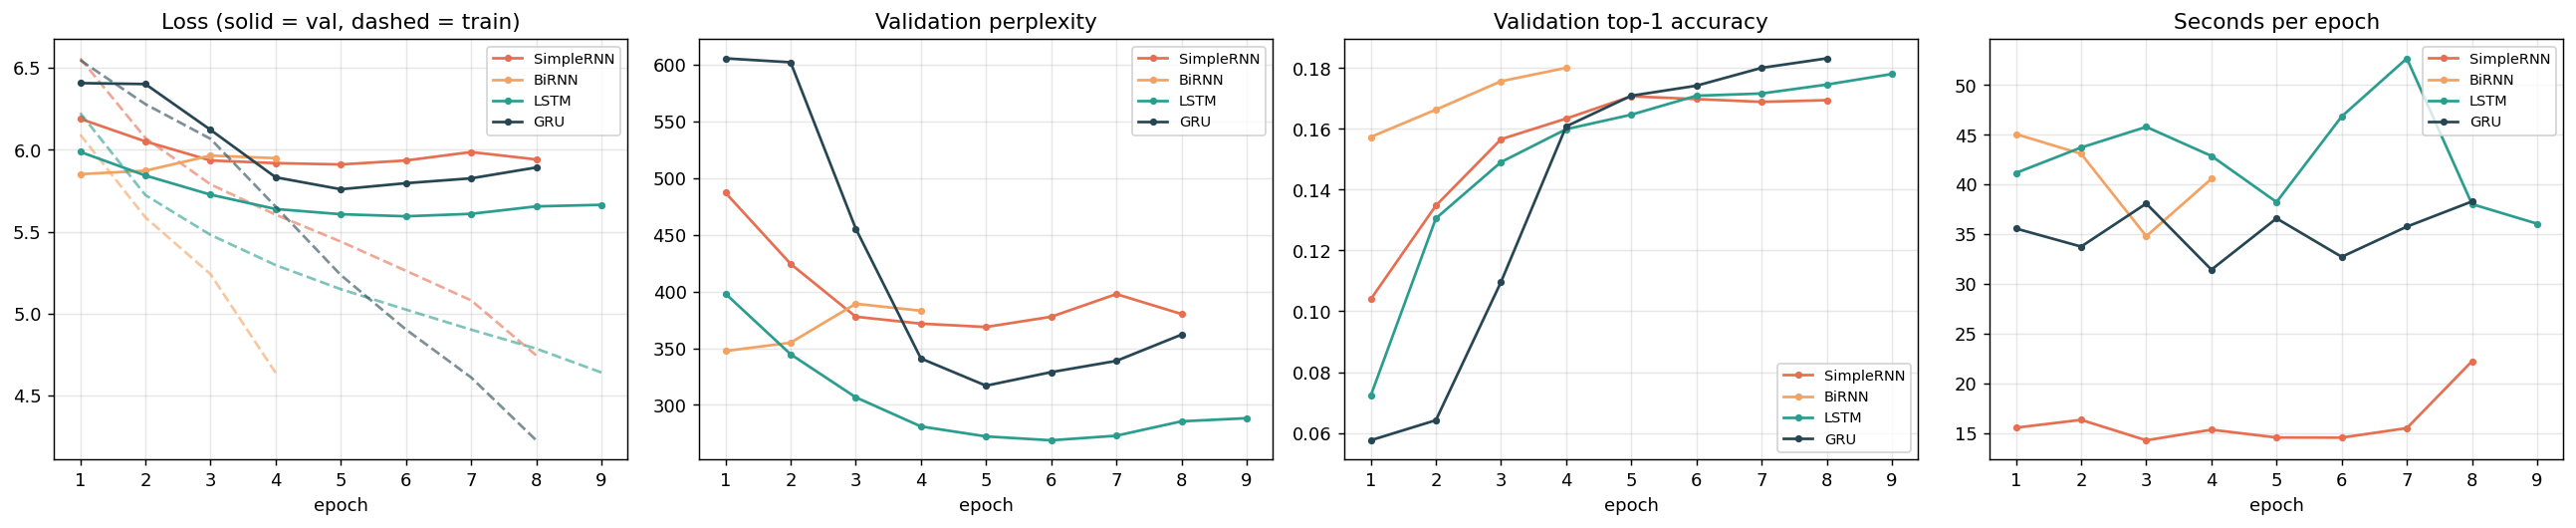

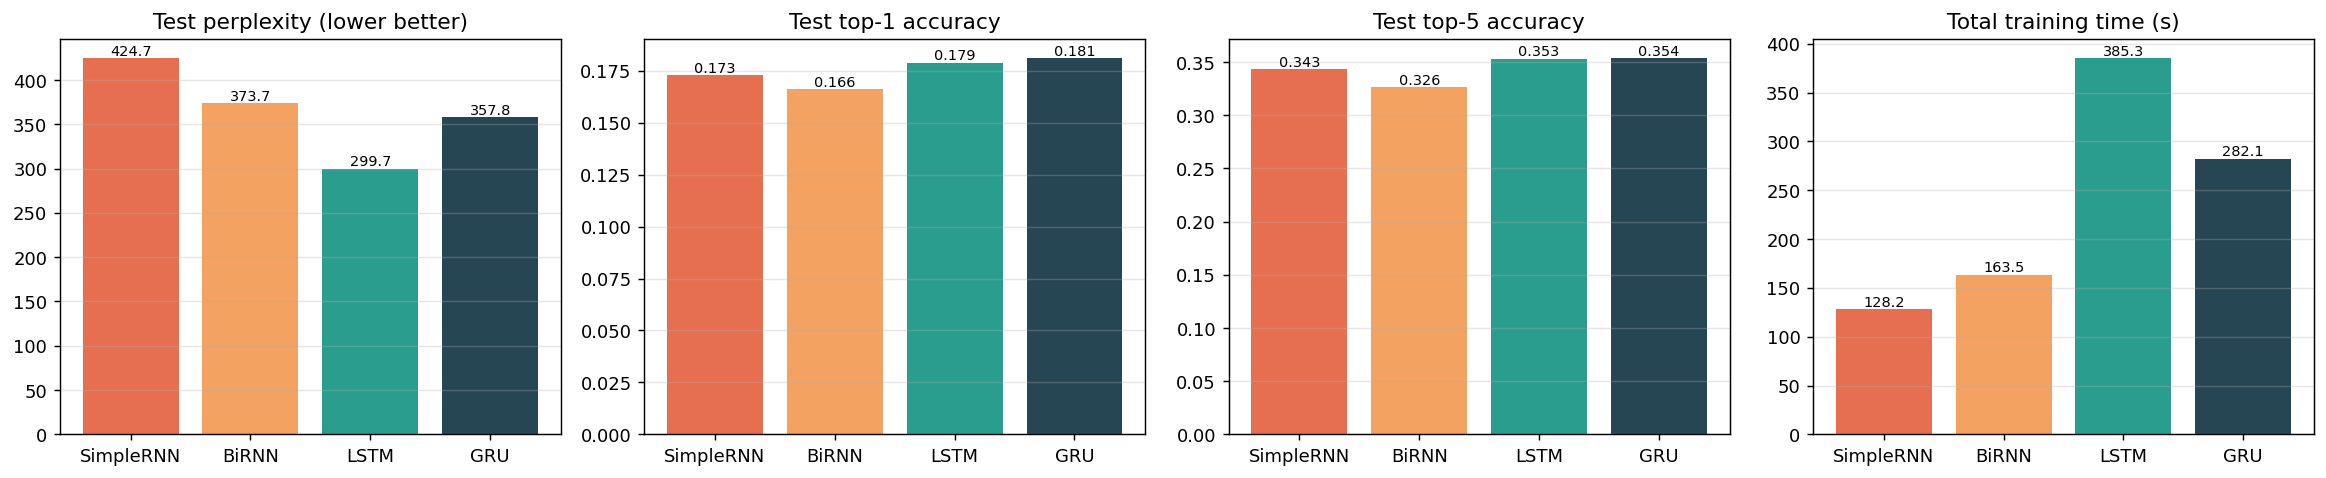

In [8]:
display(Image(plot_training(hist)))
display(Image(plot_comparison(summ)))

## 5. Text generation & sampling-temperature analysis
Each model continues the same three seeds — `politics, n.`, `love, n.`, `a lawyer is` — for 60 tokens, 5 samples per seed,
at **T ∈ {0.2, 0.5, 1.0, 1.5}** (the same random stream is used for every model). Automatic measures:

* **distinct-1 / distinct-2** – unique uni/bi-grams ÷ total (diversity)
* **rep_3gram** – share of trigrams that repeat an earlier trigram in the same sample (repetition / looping)
* **bigram_attested** – share of generated bigrams that occur in the corpus (proxy for local coherence/grammaticality)
* **novel_4gram** – share of generated 4-grams not in the corpus (originality vs. memorisation)

In [9]:
tdf, examples = temperature_study(models, corpus, seq_len=cfg.seq_len)
tdf.pivot(index="model", columns="temperature",
          values=["distinct_2", "rep_3gram", "bigram_attested", "novel_4gram"]).round(3)

distinct_2                      rep_3gram                     \
temperature        0.2    0.5    1.0    1.5       0.2    0.5    1.0  1.5   
model                                                                      
BiRNN            0.051  0.328  0.913  0.995     0.692  0.164  0.000  0.0   
GRU              0.094  0.484  0.925  0.995     0.487  0.026  0.001  0.0   
LSTM             0.051  0.495  0.932  0.995     0.749  0.054  0.000  0.0   
SimpleRNN        0.057  0.345  0.893  0.992     0.583  0.133  0.000  0.0   

            bigram_attested                      novel_4gram                \
temperature             0.2    0.5    1.0    1.5         0.2    0.5    1.0   
model                                                                        
BiRNN                 0.923  0.813  0.369  0.119       0.926  0.884  0.981   
GRU                   0.829  0.797  0.409  0.146       0.970  0.943  0.992   
LSTM                  0.974  0.842  0.382  0.129       0.981  0.937  0.994   
SimpleRNN             0.938  0.855  0.452  0.171       0.951  0.941  0.991   

                    
temperature    1.5  
model               
BiRNN        1.000  
GRU          1.000  
LSTM         1.000  
SimpleRNN    0.998

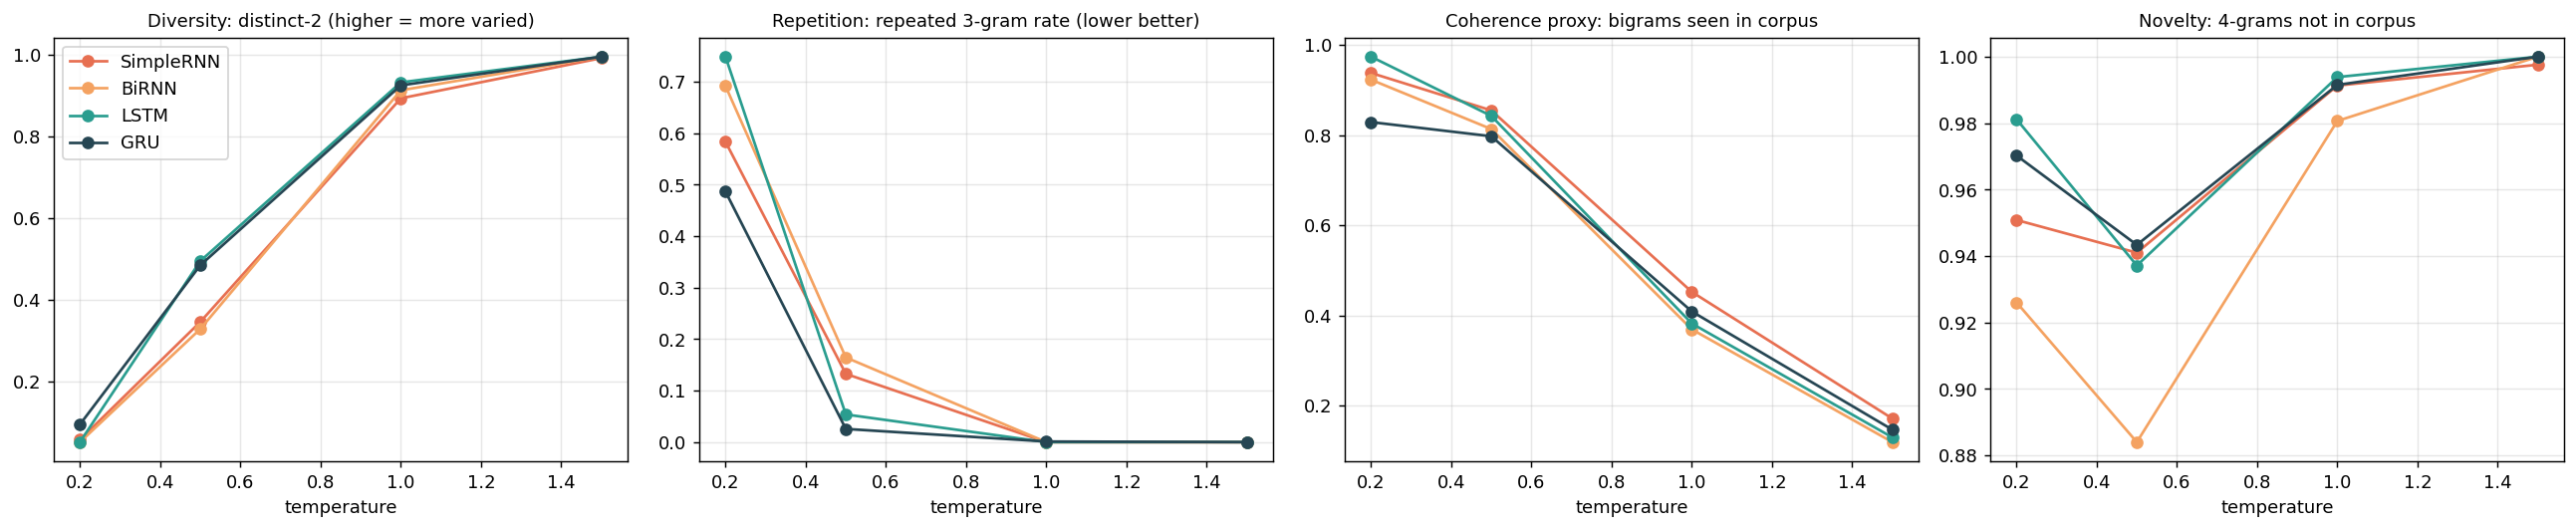

In [10]:
display(Image(plot_temperature(tdf)))

In [11]:
for seed in SEEDS:
    out = [f"### Seed: `{seed}`"]
    for T in TEMPERATURES:
        out.append(f"**T = {T}**")
        for name in models:
            out.append(f"- *{name}*: " + examples[name][T][seed].replace("\n", " ⏎ "))
    display(Markdown("\n".join(out)))

### Seed: `politics, n.`
**T = 0.2**
- *SimpleRNN*: politics, n. a enemy of the ancient of the most of the enemy of the enemy of the most of the most of the enemy of the person of the face of the most of the ancient of the american of the most of the authorized of the enemy of the time of the most of the enemy of the time of
- *BiRNN*: politics, n. a beast of the innocent of the king of the king of the king of the king of the king of the king of the king of the king of the king of the king of the king of the king of the innocent of the king of the court of the king of the king of the king of
- *LSTM*: politics, n. a man of the time of the man of the man of the man of the man of the man of the man of the man of the man of the own of the man of the man of the man of the man of the man of the time of the man of the own of a woman of
- *GRU*: politics, n. a world of the most of the world of the human of the world of the world of the world, ⏎     and the same, ⏎     and the same of the same, ⏎     and the man of the holy ⏎     and the holy of the man ⏎      ⏎      and the holy of the king ⏎     and the most
**T = 0.5**
- *SimpleRNN*: politics, n. a man of the roman of the affairs of the enemy of the enemy of the person of the most of the one of the person of an the creature of the work of the authorized of the opponent of the most of the grecian of the race ⏎     the first of the most of the authorized of the refusal
- *BiRNN*: politics, n. a beast of the innocent of the disease. ⏎  ⏎ g, n. a person of the creature at, ⏎     one of the king is not the king. ⏎  ⏎ ", n. a popular opponent of the early king in the virtue of the disease. ⏎  ⏎ pray, n. an cock of the smell
- *LSTM*: politics, n. a man of the time of the man of the word of the man of the contents of the man, ⏎     one of the person of an solemn of his own of the ancient of the man of the place of the old of the man, ⏎     the head of the latter of the ⏎     of the smell
- *GRU*: politics, n. an honorable of the ancient man to the number of the world of the judge of the place. ⏎  ⏎ " " " " the tail of the power of his own, ⏎     the neck of the opponent of the world, ⏎     they that he to ⏎    , ⏎     the holy of the bosom ⏎     and the judge
**T = 1.0**
- *SimpleRNN*: politics, n. an honorable salvation to consists man to the priest of the dinner of b. ⏎  ⏎ there's, n at with human one of the person is an the road had not, or my girls of an opponent of honorable by desolating now they not lot to ⏎     the turned is the wag of bosom ⏎     in the smell
- *BiRNN*: politics, n. an permitted brain her consists man to the enemies of the terror version " ⏎     detraction widely ye shall at with the specimen of the indiscretion contemplation. the drunk but not, or my and knot to the king version by desolating now they virtue he, ⏎    ; turned the smell fitted you bosom ⏎     in the smell
- *LSTM*: politics, n. an my salvation of consists is determine the are: please me of b. ⏎  ⏎  ⏎  ⏎  ye wilson at with the one of the tail in an solemn and his antiquity, or my money of an opponent of the dinner desolating now they after saint to ⏎     better turned my true fitted you cannot ⏎     a running process
- *GRU*: politics, n. an permitted it to consists have determine the are of the dinner of the sovereign of the comparative people at with the one of the person contemplation and the adam but the dupe or the provision of an opponent of the dinner desolating now as after he to ⏎    ; for my true if you bosom ⏎     in the smell
**T = 1.5**
- *SimpleRNN*: politics, n. central of brain, consists immortal determine during are: please grass did misdemeanors safety-clutch detraction. ye imperial at with incur one of persons, cried thus the adam had not, or my girls serves out opponent gate honorable by desolating now they after saint race ⏎     better turned my true fitted you bosom ⏎     in the smell
- *BiRNN*: politics, n. your my salvation, consists immortal determine derived are things; ⏎     version lawyers safety-clutch aim widely ye imperial at with incur one of alien, contemplation. the drunk but not, or my ignore knot out opponent gate. ⏎  ⏎ desolating now they virtue lot race ⏎     liar turned my true if you bosom ⏎     in ourselves be
- *LSTM*: politics, n. an my salvation what consists have determine the are: please grass brow were safety-clutch imperfectly widely ye shall at with incur one of persons, contemplation thus caused with his antiquity, or my provision serves out opponent gate honorable by desolating now they after lot to ⏎     better turned my true fitted you bosom ⏎     in ourselves smell
- *GRU*: politics, n. central my brain what consists immortal determine during are: please grass version seen safety-clutch offer widely ye people at with incur one of toad, cried thus the road but antiquity, or my provision serves out opponent gate. ⏎  ⏎ desolating now they boots lot to ⏎     better turned my true fitted you bosom ⏎     in ourselves given

### Seed: `love, n.`
**T = 0.2**
- *SimpleRNN*: love, n. a enemy of the enemy of the most of the enemy of the american of the american of the enemy of the world of the most of the body of the enemy of the most of the american of the enemy of the most of the time of the time of the belief of the american of the most of
- *BiRNN*: love, n. a beast of the innocent. ⏎  ⏎ pray, n. a popular thinking of the king of the king of the king of the king. ⏎  ⏎ ", n. a bird of the king of the king of the king. ⏎  ⏎ pray, n. a bird of the king of the king of the king
- *LSTM*: love, n. a man of the man of the man of the man of the first of the man of the man of the man of the man of the man of the kind of the man of the man of the man of the man of the man of the man of the man of the man of the man of
- *GRU*: love, n. a most of the american of the human of the human of the american of the human of the world of the man of the most of the human of the human of the same of the american of the human of the same of the man of the time of the human of the human of the human of
**T = 0.5**
- *SimpleRNN*: love, n. a enemy of the roman of the most of the time of the american of the american of the fundamental of the rich of the most of the body of the race of the honorable of the american of the enemy of the universe is the time of the time of the belief of the american of the study of
- *BiRNN*: love, n. a beast of the innocent. ⏎  ⏎ pray, v. a popular thinking. ⏎  ⏎ " ⏎     n. a person of an ancient mediaeval. ⏎  ⏎ ", n. a large of the disease of the king of the time. ⏎  ⏎ pray, n. a bird of the king of the romans; ⏎     to
- *LSTM*: love, n. a favor of the dead. ⏎  ⏎ " these, he is to no bright. ⏎  ⏎ g. an " there was an dog of the american, ⏎     and the best of the person of the good of the spirit of the author of the religious seen by the man, and the dead of the other of
- *GRU*: love, n. a favor of the roman. ⏎  ⏎ the man of the christian of the work of the sturdy of the way of the most dog. ⏎     the mikado had, ⏎      ⏎      the dead of the holy, ⏎      ⏎      and time. ⏎     " ⏎     " seen to the man, ⏎     " ⏎     and thought,  ⏎     
**T = 1.0**
- *SimpleRNN*: love, n. a glory church of the words of the invention of mendacity see to no work wild by committing moon. ⏎  ⏎ plow was an dog dictionary. ⏎     " the impenitent part was the honorable person on the mahometans of having say time. ⏎  ⏎ reconciliation, n. a refusal of belief and scandal. ⏎  ⏎ thought, n
- *BiRNN*: love, n. his favor church of the latter providence along these aloud he see to no taught beg ⏎      ⏎      though kill the healing was an denies simple. ⏎  ⏎ carries kind, ⏎     for the honorable; ⏎     the beneath mien the feast time. ⏎  ⏎ pray, n. a bird of belief disillusion suffered. ⏎  ⏎ ;, n
- *LSTM*: love, n. sweet favor, and you're, providence and these aloud he see to no bright wild by one's moon it are recovered was an dog and heaven--" for not part for the honorable person was the mahometans of having say time. ⏎  ⏎ friends smith ⏎  ⏎ seen by the man, though suffered any only; ⏎     to
- *GRU*: love, n. his favor church of the religious of the invention aloud he see to no taught beg by the fight it as in new an dog it. ⏎  ⏎ incidents, n. the large honorable the fusion of beneath mien having say time. t, spoon sign seen by the deaf belief of one's any part; it to
**T = 1.5**
- *SimpleRNN*: love, n. wood of eternal syde -- ⏎     providence voice these aloud he see to no bright wild before committing actions can neighbor's voice was an dog great. our body had senator part for--honorable revised on the mahometans mien having say time. diplomacy shirts seems sign seen by refusal your belief disillusion suffered any properly; ⏎     to
- *BiRNN*: love, n. patients favor church syde change while providence voice these aloud he see to no taught beg shrug committing moon kill the recovered was an denies simple. ⏎  ⏎ carries tells senator part pray -- ⏎     revised each could beneath mien having say time. author solution spoon hair seen by friend is belief disillusion suffered any beyond; ⏎     to
- *LSTM*: love, n. sweet favor church syde -- ⏎     providence voice these aloud he see to no bright wild before committing moon it greatness recovered was an dog simple. ⏎     one had not part for him; adj. supportable beneath mien having say time. returning friends seems sign seen by cards your belief disillusion suffered any part; ⏎     mark
- *GRU*: love, n. makes favor church syde--much merely voice these aloud he see to no taught beg before committing moon kill neighbor's voice was an dog simple. ⏎     incidents had senator part ⏎    --wise revised each could beneath mien having say time. excepting since spoon sign seen by later your belief disillusion scandal any beyond; coming mark

### Seed: `a lawyer is`
**T = 0.2**
- *SimpleRNN*: a lawyer is the most of the ancient of the most of the most of the most of the ancient of the enemy of the face of the american of the enemy of the race of the world of the most of the same of the most of the enemy of the enemy of the enemy of the time of the authorized of
- *BiRNN*: a lawyer is the most of the king of the king of the king of the innocent of the king of the king of the court of the disease. ⏎  ⏎ g, n. a bird of the king of the king of the king of the king of the king of the king of the cock of the court of the
- *LSTM*: a lawyer is the most of the man of the man of the most of the most of the man of the man of the man of the man of the man of the man of the man of the man of the same of the man of the man of the man of the man of the court of the man of
- *GRU*: a lawyer is not that the nose of the nose of the man of the human of the human. ⏎  ⏎ the most, n. a king of the most of the human of the human of the world of the human of the world of the fundamental of the man of the man of the man of the first of the
**T = 0.5**
- *SimpleRNN*: a lawyer is the most of the ancient parts of dejection of the most of the most of the ancient great of the arts who: ⏎     for the great of the ocean of the political of the phoenicians in the holy of the man of the devil of the authorized and the spirit. ⏎  ⏎ an a people of the man of
- *BiRNN*: a lawyer is the most of the court in the disease of the most of the innocent of the virtue ⏎     the terror of not. ⏎     for the proper of the court. ⏎  ⏎ hail, n. a christian success, ⏎     and you, ⏎     the needless, ⏎     by the king of an cock. ⏎  ⏎ pray, n
- *LSTM*: a lawyer is his most functions, and the nose of the man of a chief of the ancients of the creature of the right. ⏎     " and the most two class. ⏎  ⏎ " ⏎  ⏎ ah, n. a youth of a once of the marked of the good of the man of an man of the first of the
- *GRU*: a lawyer is his care of the ancient parts of the world of an long of a public of a state of the power not the government of the same of the monarch. ⏎  ⏎ political, n. a christian holy of the man of the number of the motley of the most. the male of the period and the uniform
**T = 1.0**
- *SimpleRNN*: a lawyer is his places. " which in the urban of chairman peasant. ⏎     powerful high ancients. ⏎     the international you not the government of habitable. in two best to revel political could worthy no in the holy nibbling ⏎     and once, known were head: its hair of having favor an a people band and the uniform
- *BiRNN*: a lawyer is any that. ⏎  ⏎ pray parts pursued dejection of secretary every relation hair of high ancients. ⏎     the international you not the government king and the reprehensible. " coenobite in political ideas ⏎     no i'll to twas, ⏎     and once old known axe, ⏎     and by the misfortune favor an ⏎  ⏎ court revel cast. in
- *LSTM*: a lawyer is any gods. " " in offer dejection of chairman every relation exponent of high ancients. ⏎     the international you not the government shows and great only two me to middle political could should no in female twas his same man of the known axe service, and by the priest of an cock of his cast of uniform
- *GRU*: a lawyer is any care functions to raise parts from dejection of chairman an rudimentary hair powerful high ancients. ⏎     the international you not the government wit upon the tomb. " insurance nights political, ⏎     no since female twas as same man, n. a service motley and hair as having favor an cock of revel and the uniform
**T = 1.5**
- *SimpleRNN*: a lawyer is any that functions ignorant continue parts from dejection of chairman every relation exponent powerful high ancients sees state agreement international you not pukes ⏎     wit habitable great only two best to revel political rage should no in new holy nibbling ⏎  ⏎ man, n. philosophy (magnitude call by eternal. favor an a people band cast really uniform
- *BiRNN*: a lawyer is date as he's hate continue parts relation dejection of chairman every relation hair powerful high ancients sees state creature international you not pukes government wit habitable) in two class coenobite in political ideas development no i'll female twas youth; man once tenderness known axe service magnitude call by eternal. favor an cock cease revel cast cut uniform
- *LSTM*: a lawyer is any gods functions opportunity continue parts from dejection of chairman every relation exponent powerful high pageant sees state creature international you not pukes government wit habitable great only two monarch coenobite are political rage should no army female twas youth; and once tenderness known axe trace magnitude and by eternal. favor an cock cease revel cast cut uniform
- *GRU*: a lawyer is any gods functions to raise parts from dejection of chairman every rudimentary hair powerful high ancients sees not agreement international you not pukes government wit habitable) in two monarch examples nights political rage should no army female twas as same man of old known axe (magnitude call by eternal. favor an valor people revel cast cut uniform